# What pushes a Batman story up BatChat's list?

Which creators, characters and publication patterns shape the model's predictions—and do the outside audiences show similar patterns?

**Rank 1 is best.** Read effect size alongside frequency and uncertainty.

By [Dan Ofer](https://scholar.google.com/citations?user=uDx2ItYAAAAJ) · [Dataset](https://www.kaggle.com/datasets/danofer/batchat-batman-rankings)

In [1]:
from itertools import pairwise
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import DisjointSet
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Kaggle mounts the dataset under /kaggle/input; locally, `make share` stages it in data/kaggle.
DATA = next(
    p.parent
    for root in ["/kaggle/input", "data/kaggle", "../data/kaggle"]
    for p in Path(root).rglob("stories.csv")
)
sns.set_theme(
    style="ticks",
    font_scale=1.05,
    rc={
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "axes.titlepad": 12,
        "figure.dpi": 120,
        "savefig.dpi": 200,
    },
)
BLUE, ORANGE, GREY = "#2767A0", "#D57927", "#75818C"

stories = pd.read_csv(DATA / "stories.csv").merge(
    pd.read_csv(DATA / "story_features.csv"), on="story_id", validate="one_to_one"
)
issues = pd.read_csv(DATA / "issues.csv")
N = len(stories)
# Higher = more liked, so weights read the same way for BatChat and for star ratings.
stories["batchat_score"] = N - stories["rank"]

## Size, direction and support

A large coefficient need not matter often. The SHAP panel separates overall influence from direction when present, with story/group counts, sampling intervals and variation across held-out fits.

## Inputs

The ridge model uses publication year, issue count, format, selected-story creators and cast. Names need five training stories to receive a coefficient. These correlated inputs describe associations within the ranked sample.

In [2]:
ROLES = ["writers", "pencilers", "inkers", "colorists", "letterers", "editors"]
NAMES = {"narrative_" + r: r[:-1] for r in ROLES}  # column -> label, e.g. "writer"
CAST = {"featured_entity_ids": "featured", "antagonists_entity_ids": "antagonist"}
WHEN = ["cover_year_start", "issue_count"]

X = stories[["medium", "format_hint", *WHEN, *NAMES, *CAST]].copy()
X[[*NAMES, *CAST]] = X[[*NAMES, *CAST]].fillna("")


def model(min_df=5):
    """Ridge regression on scaled numbers, one-hot format, and 0/1 name columns."""
    return make_pipeline(
        ColumnTransformer(
            [
                ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), WHEN),
                (
                    "format",
                    OneHotEncoder(handle_unknown="ignore", min_frequency=3),
                    ["medium", "format_hint"],
                ),
                *[
                    (
                        label,
                        CountVectorizer(
                            token_pattern=r"[^|]+", lowercase=False, binary=True, min_df=min_df
                        ),
                        col,
                    )
                    for col, label in {**NAMES, **CAST}.items()
                ],
            ]
        ),
        RidgeCV(alphas=np.logspace(-1, 3, 9)),
    )


def pretty(feature):
    """'writer__Frank Miller' -> 'Frank Miller (writer)'; characters lose their universe tag."""
    kind, _, value = feature.partition("__")
    if kind in {"num", "format"}:
        return (
            value.replace("format_hint_", "format: ")
            .replace("cover_year_start", "cover year")
            .replace("issue_count", "issue count")
        )
    return f"{value.split(' (')[0]} ({kind})"


def weights_of(fitted):
    """Keep distinct continuity coefficients separate; only actual SHAP contributions are summed."""
    labels = []
    for feature in fitted[0].get_feature_names_out():
        kind, _, value = feature.partition("__")
        labels.append(pretty(feature) if kind in {"num", "format"} else f"{value} ({kind})")
    return pd.Series(fitted[-1].coef_, index=labels)


def weight_bars(ax, weights, n, faded=()):
    """Horizontal bars of the n strongest positive and negative weights; `faded` names drawn grey."""
    top = pd.concat([weights.nlargest(n), weights.nsmallest(n)]).sort_values()
    colors = [GREY if name in faded else (BLUE if v > 0 else ORANGE) for name, v in top.items()]
    ax.barh(top.index, top, color=colors)
    ax.axvline(0, color=GREY, lw=1)
    ax.xaxis.set_major_locator(MaxNLocator(5))

## 1. Fitted coefficients

Positive coefficients point toward a better predicted rank. Grey marks coefficients failing the five-fold stability filter.

Continuity versions stay separate here. Adding their coefficients would describe activating every version together; the SHAP analysis instead combines their actual contributions story by story.

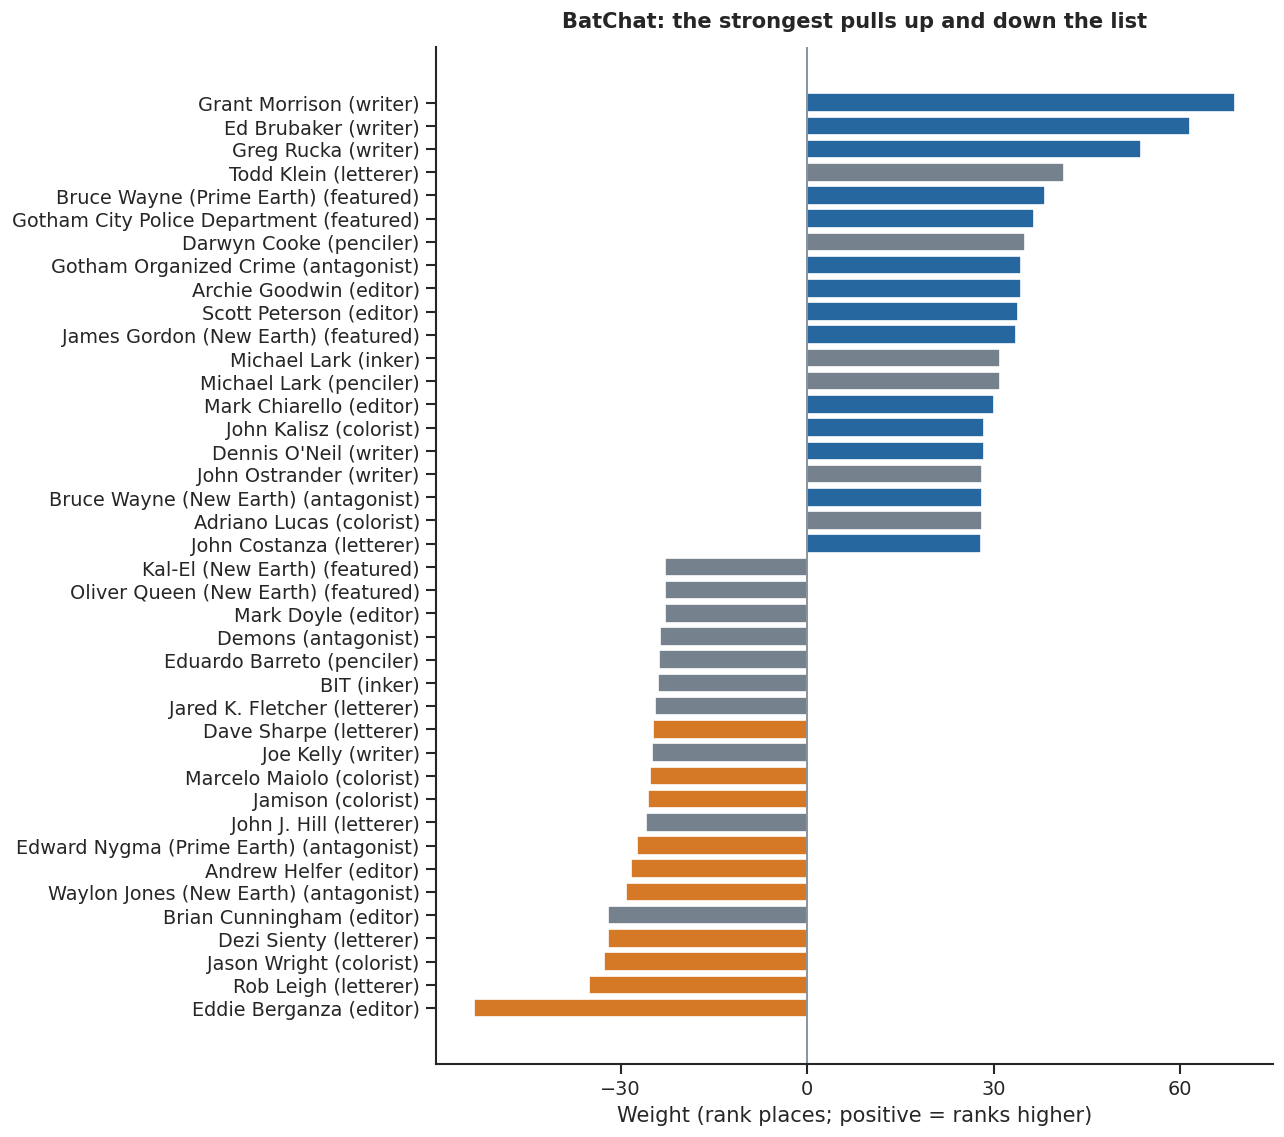

On stories it never saw, the model misses by about 173 places. 58 names passed the stability check.


In [3]:
# Stories that share an issue or a podcast episode stay in the same fold, so a model is never
# tested on the other half of an arc it trained on.
links = pd.concat(
    [
        pd.DataFrame({"story_id": stories.story_id, "key": "episode " + stories.episode_url}),
        pd.DataFrame(
            {"story_id": issues.story_id, "key": "issue " + issues.issue_id.astype("string")}
        ),
    ]
).dropna()
linked = DisjointSet(stories.story_id)
for _, ids in links.groupby("key").story_id:
    for a, b in pairwise(ids):
        linked.merge(a, b)
label = {story: min(group) for group in linked.subsets() for story in group}
groups = stories.story_id.map(label).to_numpy()
folds = list(GroupKFold(n_splits=5, shuffle=True, random_state=42).split(X, groups=groups))

y = stories.batchat_score
batchat_model = model().fit(X, y)
batchat_weights = weights_of(batchat_model)

# One fit per fold does triple duty: held-out predictions, the shuffle test, and the stability test.
blocks = {
    "Year + length": WHEN,
    "Format": ["medium", "format_hint"],
    "Writers": ["narrative_writers"],
    "Pencilers + inkers": ["narrative_pencilers", "narrative_inkers"],
    "Colors + letters + editors": [
        "narrative_colorists",
        "narrative_letterers",
        "narrative_editors",
    ],
    "Characters": list(CAST),
}
held_out = np.empty(N)
fold_models = []
shuffle_cost, fold_weights = [], []
rng = np.random.default_rng(0)
for k, (train, test) in enumerate(folds):
    fitted = model().fit(X.iloc[train], y.iloc[train])
    held_out[test] = fitted.predict(X.iloc[test])
    fold_models.append(fitted)
    fold_weights.append(weights_of(fitted).rename(k))
    base = mean_absolute_error(y.iloc[test], held_out[test])
    for block, cols in blocks.items():
        shuffled = X.iloc[test].copy()
        shuffled[cols] = shuffled[cols].sample(frac=1, random_state=rng.integers(1e6)).to_numpy()
        shuffle_cost.append(
            {
                "block": block,
                "worse by": mean_absolute_error(y.iloc[test], fitted.predict(shuffled)) - base,
            }
        )
shuffle_cost = pd.DataFrame(shuffle_cost)
fold_weights = pd.concat(fold_weights, axis=1).fillna(0)
stable = fold_weights.index[
    (np.sign(fold_weights).nunique(axis=1) == 1) & (fold_weights.abs().min(axis=1) > 10)
]
unstable = set(batchat_weights.index) - set(stable)

fig, ax = plt.subplots(figsize=(9, 11))
weight_bars(ax, batchat_weights, 20, faded=unstable)
ax.set(
    xlabel="Weight (rank places; positive = ranks higher)",
    title="BatChat: the strongest pulls up and down the list",
)
plt.show()
print(
    f"On stories it never saw, the model misses by about {mean_absolute_error(y, held_out):.0f} places. "
    f"{len(stable)} names passed the stability check."
)

Compare coefficients with the observed rank distributions: the same writer's books can span most of the list.

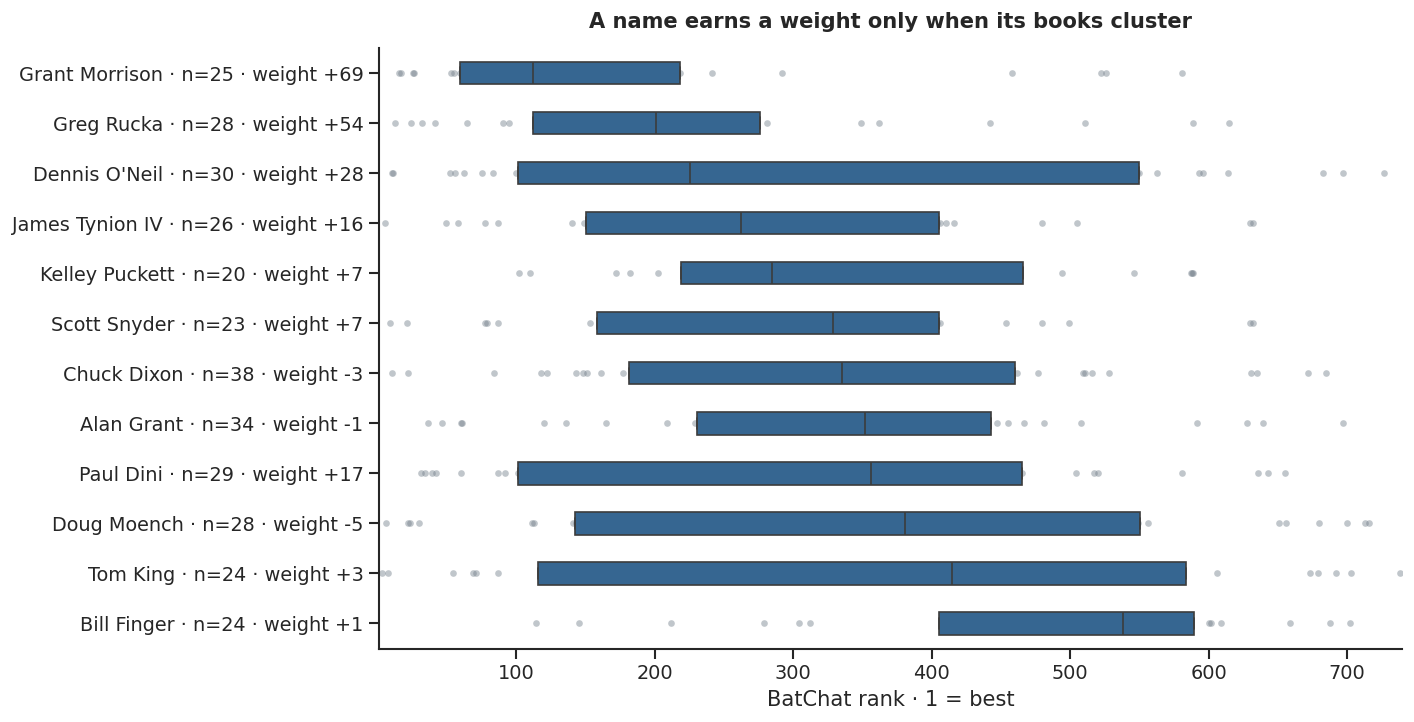

In [4]:
writers = stories.assign(writer=stories.narrative_writers.str.split("|")).explode("writer")
top = writers.writer.value_counts().head(12).index
chart = writers[writers.writer.isin(top)]
order = chart.groupby("writer")["rank"].median().sort_values().index
labels = {
    w: f"{w} · n={chart.writer.eq(w).sum()} · weight {batchat_weights.get(f'{w} (writer)', 0):+.0f}"
    for w in order
}
chart = chart.assign(label=chart.writer.map(labels))
fig, ax = plt.subplots(figsize=(11, 6.5))
common = dict(data=chart, x="rank", y="label", order=[labels[w] for w in order], ax=ax)
sns.stripplot(**common, color=GREY, alpha=0.45, size=4, jitter=False, zorder=0)
sns.boxplot(**common, color=BLUE, whis=0, showfliers=False, width=0.45)
ax.set(
    xlabel="BatChat rank · 1 = best",
    ylabel="",
    xlim=(1, N),
    title="A name earns a weight only when its books cluster",
)
plt.show()

## 2. How stable are those weights?

The shuffle test disrupts one input block in held-out stories and measures the increase in prediction error. The stability filter refits five times, retaining coefficients whose sign stays fixed and magnitude exceeds ten rank places in every fit.

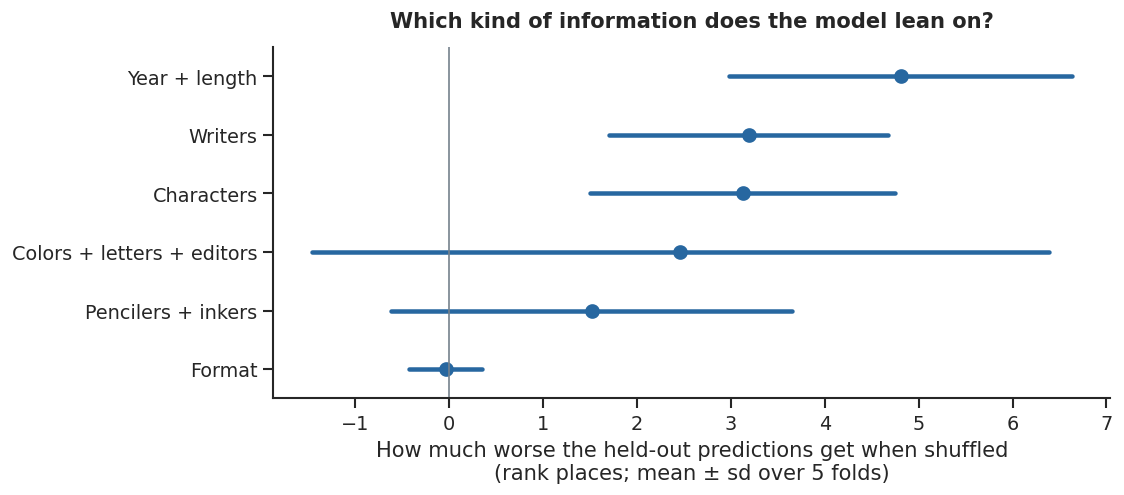

In [5]:
order = shuffle_cost.groupby("block")["worse by"].mean().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(9, 3.8))
sns.pointplot(
    data=shuffle_cost,
    x="worse by",
    y="block",
    order=order,
    errorbar="sd",
    linestyle="none",
    color=BLUE,
    ax=ax,
)
ax.axvline(0, color=GREY, lw=1)
ax.set(
    xlabel="How much worse the held-out predictions get when shuffled\n(rank places; mean ± sd over 5 folds)",
    ylabel="",
    title="Which kind of information does the model lean on?",
)
plt.show()

Year and length form one shuffled block, so this test cannot separate their effects. The typical prediction miss is about 170 places; changes of a few places are modest.

## 2a. Big effect, or a frequently useful feature?

A coefficient describes a unit change. **Mean absolute held-out SHAP** measures how much a feature contributes across this actual set of stories, including when it is absent. A rare feature can have a large coefficient but little overall influence.

The left panel ranks features by that overall magnitude. The right shows the **signed mean contribution when present**: positive points toward a higher BatChat score (a better rank), negative toward a worse one. Continuous features use all stories, so their signed average can be near zero even when they matter greatly.

Each label gives the observed story count and the number of linked issue/episode groups containing it. Thin intervals are **95% cluster-bootstrap intervals** for the signed mean, holding the fitted predictions fixed; fewer than five groups gets no interval. The table adds the range across five held-out folds and the number of fits that retained the feature. Wide ranges, few groups, or omission from some fits are reasons for caution—not evidence of a precise effect.

Credits and characters are correlated, so these are model attributions, not causal effects. Continuity variants are combined within each displayed name and role before taking absolute values. Missing cast or credits are not verified absences.

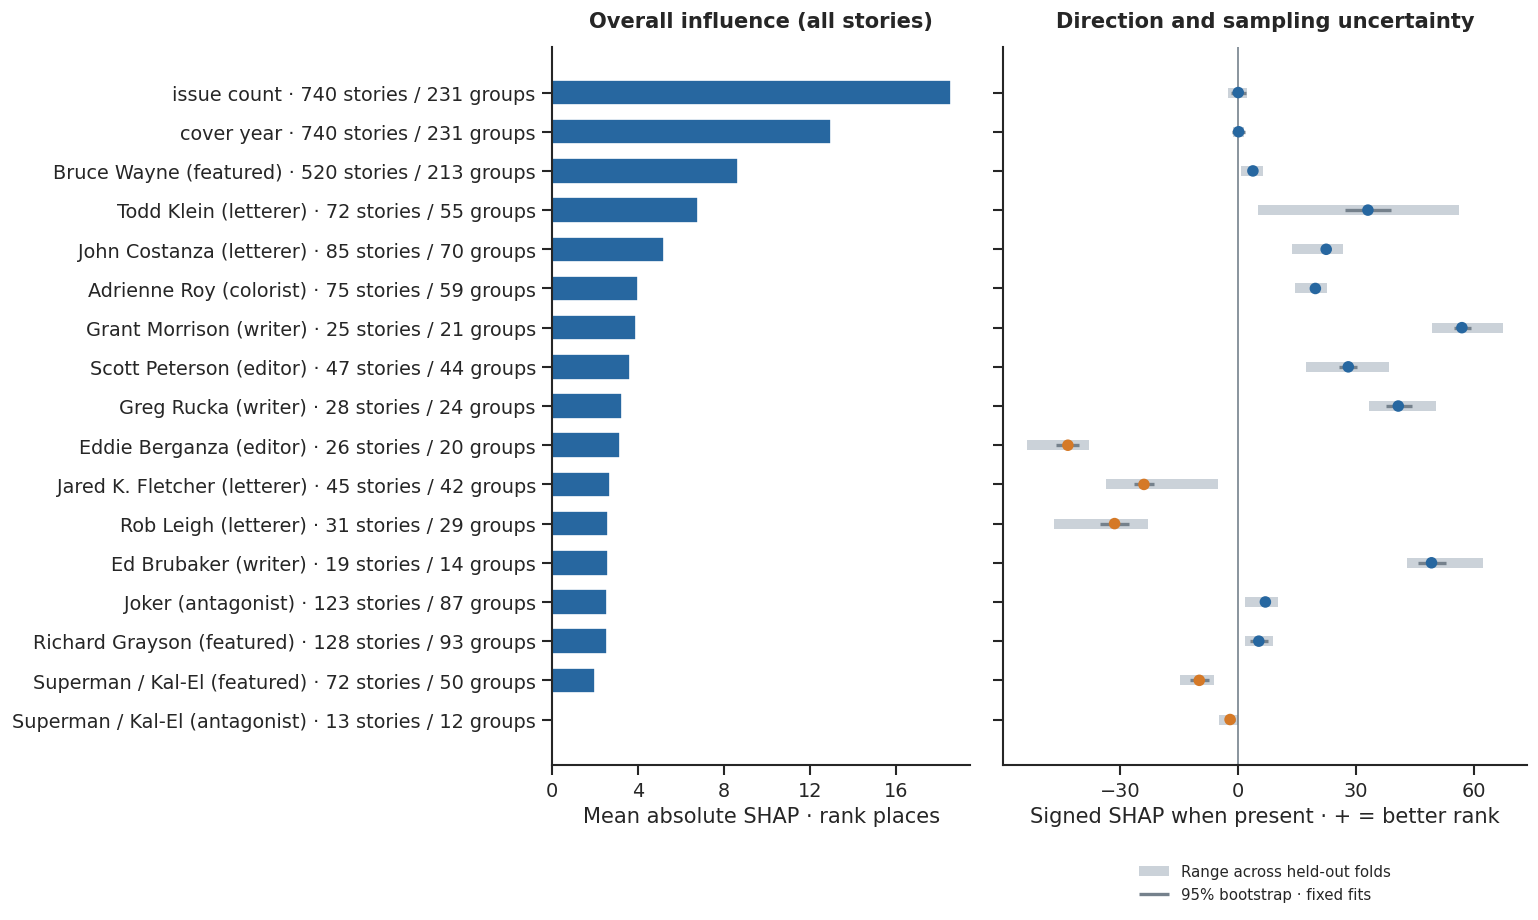

,Stories,Groups,Fits retaining feature,Mean |SHAP| (all),Mean |SHAP| (present),Signed mean (present),Fold minimum,Fold maximum,Folds with presence
issue count,740,231,5,18.5,18.5,0.0,-2.6,2.3,5
cover year,740,231,5,13.0,13.0,0.1,-1.2,1.5,5
Bruce Wayne (featured),520,213,5,8.6,9.1,3.8,0.6,6.3,5
Todd Klein (letterer),72,55,5,6.8,33.0,33.0,5.1,56.2,5
John Costanza (letterer),85,70,5,5.2,22.4,22.4,13.8,26.7,5
Adrienne Roy (colorist),75,59,5,4.0,19.7,19.7,14.6,22.7,5
Grant Morrison (writer),25,21,5,3.9,57.0,57.0,49.3,67.4,5
Scott Peterson (editor),47,44,5,3.6,28.1,28.1,17.2,38.5,5
Greg Rucka (writer),28,24,5,3.3,40.8,40.8,33.3,50.4,5
Eddie Berganza (editor),26,20,5,3.2,43.3,-43.3,-53.7,-37.9,5


Kal-El is indexed as featured or antagonist in 75 of 740 stories (53 validation groups). Roles above overlap; do not add their counts.
Counts cover Kal-El continuity variants in those two input fields; Kal-L variants and robots are separate names.


In [6]:
# Exact interventional SHAP for a linear model, relative to each training-fold mean.
# Keep zero contributions where a fold never learned a rare feature.
shap_parts, fold_ids, learned = [], np.empty(N, dtype=int), []
for k, (fitted, (train, test)) in enumerate(zip(fold_models, folds)):
    train_features = fitted[0].transform(X.iloc[train])
    test_features = fitted[0].transform(X.iloc[test])
    train_features = (
        train_features.toarray() if hasattr(train_features, "toarray") else train_features
    )
    test_features = test_features.toarray() if hasattr(test_features, "toarray") else test_features
    center = train_features.mean(axis=0)
    values = (test_features - center) * fitted[-1].coef_
    baseline = fitted[-1].intercept_ + center @ fitted[-1].coef_
    assert np.allclose(baseline + values.sum(axis=1), held_out[test])
    names = fitted[0].get_feature_names_out()
    shap_parts.append(
        pd.DataFrame(values, index=test, columns=names)
        .rename(columns=pretty)
        .T.groupby(level=0)
        .sum()
        .T
    )
    learned.append(set(map(pretty, names)))
    fold_ids[test] = k
held_shap = pd.concat(shap_parts).fillna(0).sort_index()

# Count raw observed names, including those below a fold's vocabulary threshold.
observed = {}
for column, kind in {**NAMES, **CAST}.items():
    for i, values in enumerate(X[column]):
        for token in values.split("|"):
            if token:
                observed.setdefault(pretty(kind + "__" + token), set()).add(i)
# Non-name features use their transformed nonzero indicator; continuous features use all rows.
presence = pd.DataFrame(False, index=stories.index, columns=held_shap.columns)
for name, rows in observed.items():
    if name in presence:
        presence.loc[list(rows), name] = True
for k, (fitted, (_, test)) in enumerate(zip(fold_models, folds)):
    values = fitted[0].transform(X.iloc[test])
    values = values.toarray() if hasattr(values, "toarray") else values
    for j, feature in enumerate(fitted[0].get_feature_names_out()):
        if feature.startswith("format__"):
            presence.loc[test, pretty(feature)] = values[:, j] != 0
presence[["cover year", "issue count"]] = True
support = pd.DataFrame(
    {
        "Stories": presence.sum(),
        "Groups": {name: len(set(groups[presence[name].to_numpy()])) for name in presence},
        "Mean |SHAP| (all)": held_shap.abs().mean(),
        "Mean |SHAP| (present)": held_shap.abs().where(presence).mean(),
        "Signed mean (present)": held_shap.where(presence).mean(),
        "Fits retaining feature": {
            name: sum(name in names for names in learned) for name in held_shap
        },
    }
)
fold_means = held_shap.where(presence).groupby(fold_ids).mean()
support["Fold minimum"] = fold_means.min()
support["Fold maximum"] = fold_means.max()
support["Folds with presence"] = fold_means.notna().sum()
# Top 15 overall, plus both Superman roles even when outside the top 15.
selected = list(support.nlargest(15, "Mean |SHAP| (all)").index)
selected += [name for name in support.index if name.startswith("Kal-El (") and name not in selected]
chart = support.loc[selected].sort_values("Mean |SHAP| (all)", ascending=False).copy()

# Resample connected issue/episode groups together, preserving their within-group stories.
group_sums = held_shap[selected].where(presence[selected], 0).groupby(groups).sum()
group_counts = presence[selected].groupby(groups).sum()
rng = np.random.default_rng(42)
weights = rng.multinomial(len(group_sums), np.full(len(group_sums), 1 / len(group_sums)), size=1000)
counts = weights @ group_counts.to_numpy()
means = np.divide(
    weights @ group_sums.to_numpy(), counts, out=np.full(counts.shape, np.nan), where=counts > 0
)
intervals = pd.DataFrame(
    np.nanquantile(means, [0.025, 0.975], axis=0).T, index=selected, columns=["95% low", "95% high"]
)
chart = chart.join(intervals)
chart.loc[chart.Groups.lt(5), ["95% low", "95% high"]] = np.nan

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 0.38 * len(chart) + 1.4),
    sharey=True,
    gridspec_kw={"width_ratios": [1, 1.25]},
)
ypos = np.arange(len(chart))
labels = [
    f"{name.replace('Kal-El', 'Superman / Kal-El')} · {int(row.Stories)} stories / {int(row.Groups)} groups"
    for name, row in chart.iterrows()
]
axes[0].barh(ypos, chart["Mean |SHAP| (all)"], color=BLUE, height=0.65)
axes[0].set(
    yticks=ypos,
    yticklabels=labels,
    xlabel="Mean absolute SHAP · rank places",
    title="Overall influence (all stories)",
)
colors = np.where(chart["Signed mean (present)"].ge(0), BLUE, ORANGE)
axes[1].hlines(
    ypos,
    chart["Fold minimum"],
    chart["Fold maximum"],
    color="#CBD2D9",
    linewidth=6,
    label="Range across held-out folds",
)
axes[1].hlines(
    ypos,
    chart["95% low"],
    chart["95% high"],
    color=GREY,
    linewidth=2,
    label="95% bootstrap · fixed fits",
)
axes[1].scatter(chart["Signed mean (present)"], ypos, c=colors, s=35, zorder=3)
axes[1].axvline(0, color=GREY, linewidth=1)
axes[1].set(
    xlabel="Signed SHAP when present · + = better rank", title="Direction and sampling uncertainty"
)
for ax in axes:
    ax.xaxis.set_major_locator(MaxNLocator(5))
axes[1].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=9)
axes[0].invert_yaxis()
fig.tight_layout()
plt.show()

from IPython.display import HTML, display

columns = [
    "Stories",
    "Groups",
    "Fits retaining feature",
    "Mean |SHAP| (all)",
    "Mean |SHAP| (present)",
    "Signed mean (present)",
    "Fold minimum",
    "Fold maximum",
    "Folds with presence",
]
display(
    HTML(
        "<details><summary>Support and fold stability for the plotted features</summary>"
        + chart[columns].round(1).to_html()
        + "</details>"
    )
)
superman = [name for name in observed if name.startswith("Kal-El (")]
superman_rows = set().union(*(observed[name] for name in superman))
print(
    f"Kal-El is indexed as featured or antagonist in {len(superman_rows)} of {N} stories "
    f"({len(set(groups[list(superman_rows)]))} validation groups). Roles above overlap; do not add their counts."
)
print(
    "Counts cover Kal-El continuity variants in those two input fields; Kal-L variants and robots are separate names."
)

Bootstrap intervals describe sampling variation conditional on these fits. The pale fold ranges show sensitivity to the training split; neither is a causal confidence interval. Counts and omitted fits are especially useful for judging rare names.

Superman's count covers indexed Kal-El appearances in the featured/antagonist inputs. Missing cast lists are not confirmed absences.

## 3. Readers and critics

The table separates ratings found, complete same-story matches and the final review-count screen. The outside audiences cover different books; these are exploratory comparisons. A name needs three training stories here.

Panels show the strongest coefficients in each audience's own units, keeping continuity variants separate.

,Any rating,Same story + complete,Passes review minimum
Audience,,,
Goodreads readers (stars),70,52,52
RoundUp readers (score /10),390,271,147
RoundUp critics (score /10),227,149,110


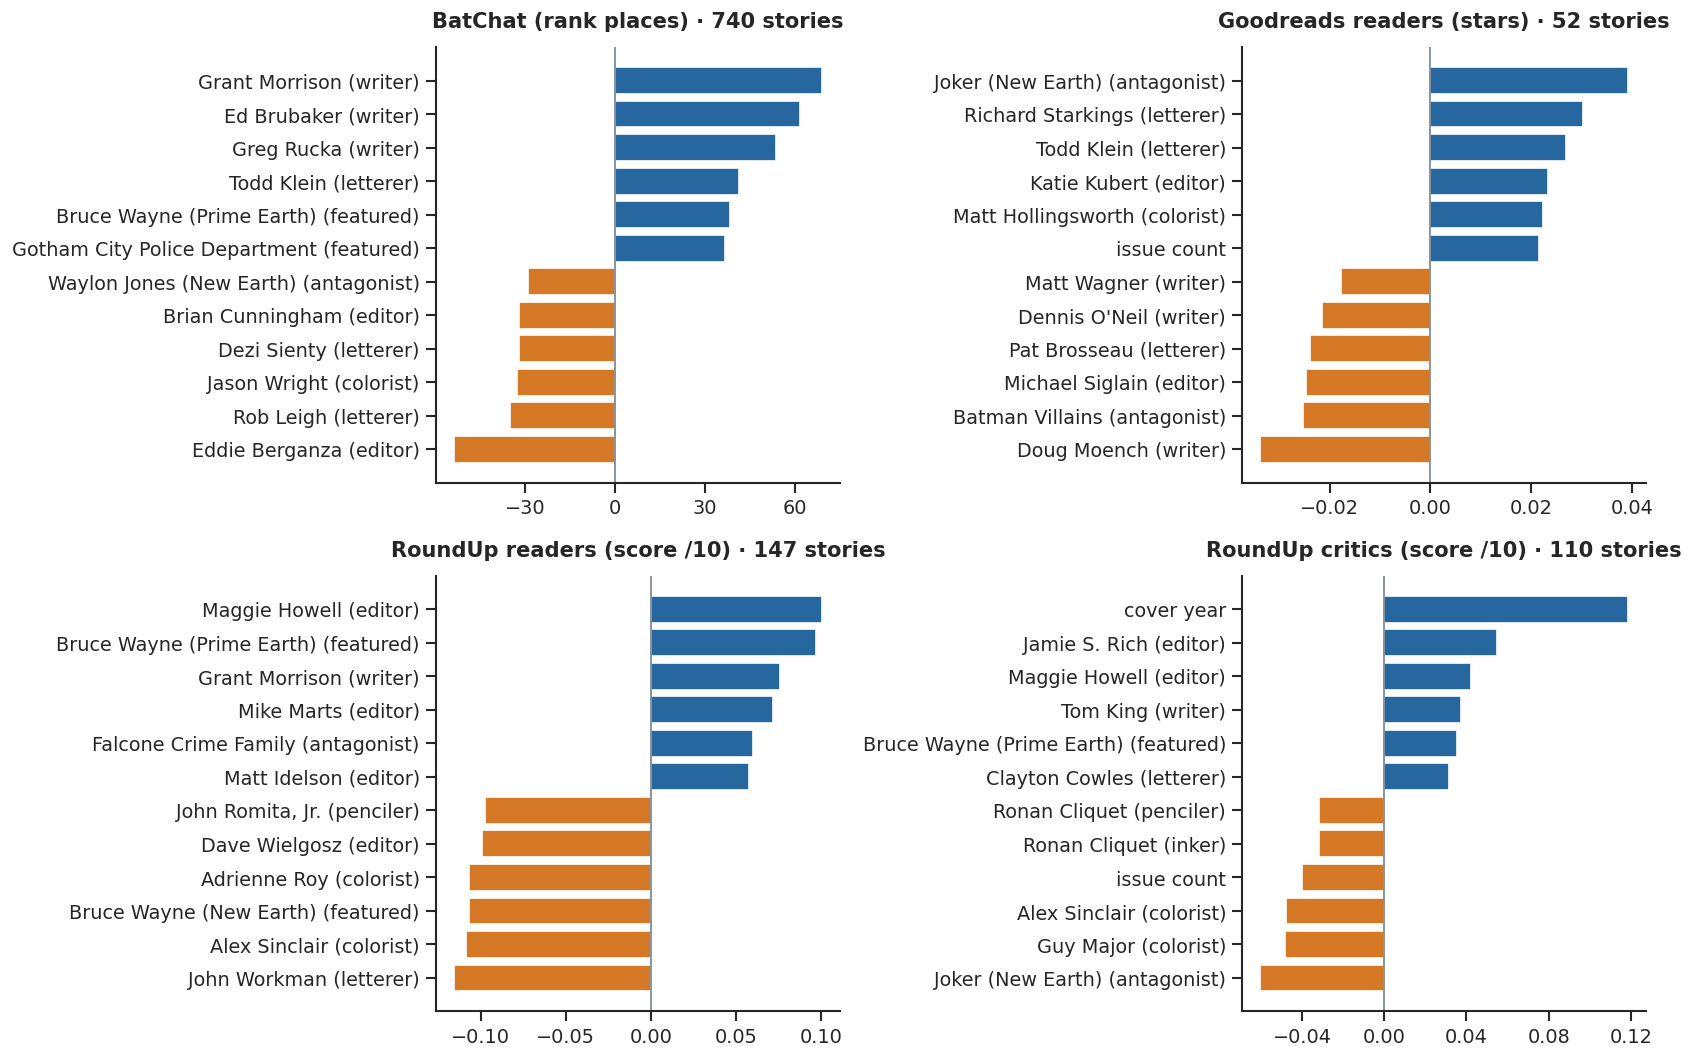

In [7]:
goodreads_ok = stories.goodreads_match_scope.eq("same_story") & stories.goodreads_rating_count.ge(
    100
)
roundup_ok = stories.roundup_narrative_scope.eq("all_indexed_narratives")
audiences = {
    "Goodreads readers (stars)": ("goodreads_rating", goodreads_ok),
    "RoundUp readers (score /10)": (
        "roundup_user_rating",
        roundup_ok & stories.roundup_user_complete & stories.roundup_user_min_count.ge(5),
    ),
    "RoundUp critics (score /10)": (
        "roundup_critic_rating",
        roundup_ok & stories.roundup_critic_complete & stories.roundup_critic_min_count.ge(3),
    ),
}
# Acquisition coverage and the final comparison sample are different counts.
coverage = []
for label, (score, ok) in audiences.items():
    if label.startswith("Goodreads"):
        comparable = stories.goodreads_match_scope.eq("same_story")
    else:
        audience = "critic" if "critic" in label.lower() else "user"
        comparable = roundup_ok & stories[f"roundup_{audience}_complete"]
    coverage.append(
        {
            "Audience": label,
            "Any rating": int(stories[score].notna().sum()),
            "Same story + complete": int((comparable & stories[score].notna()).sum()),
            "Passes review minimum": int(ok.sum()),
        }
    )
from IPython.display import display

display(pd.DataFrame(coverage).set_index("Audience"))

audience_weights = {"BatChat (rank places)": batchat_weights}
for label, (target, ok) in audiences.items():
    audience_weights[label] = weights_of(model(min_df=3).fit(X[ok], stories.loc[ok, target]))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (label, w) in zip(axes.flat, audience_weights.items()):
    weight_bars(ax, w, 6)
    n = N if label.startswith("BatChat") else audiences[label][1].sum()
    ax.set_title(f"{label} · {n} stories")
fig.tight_layout()
plt.show()

## 4. Individual mismatches

Each panel uses the held-out fit that made that prediction. Left: the hosts liked the story more than predicted; right: less. Bars show the largest contributions from present features, so the displayed subset does not sum to the prediction.

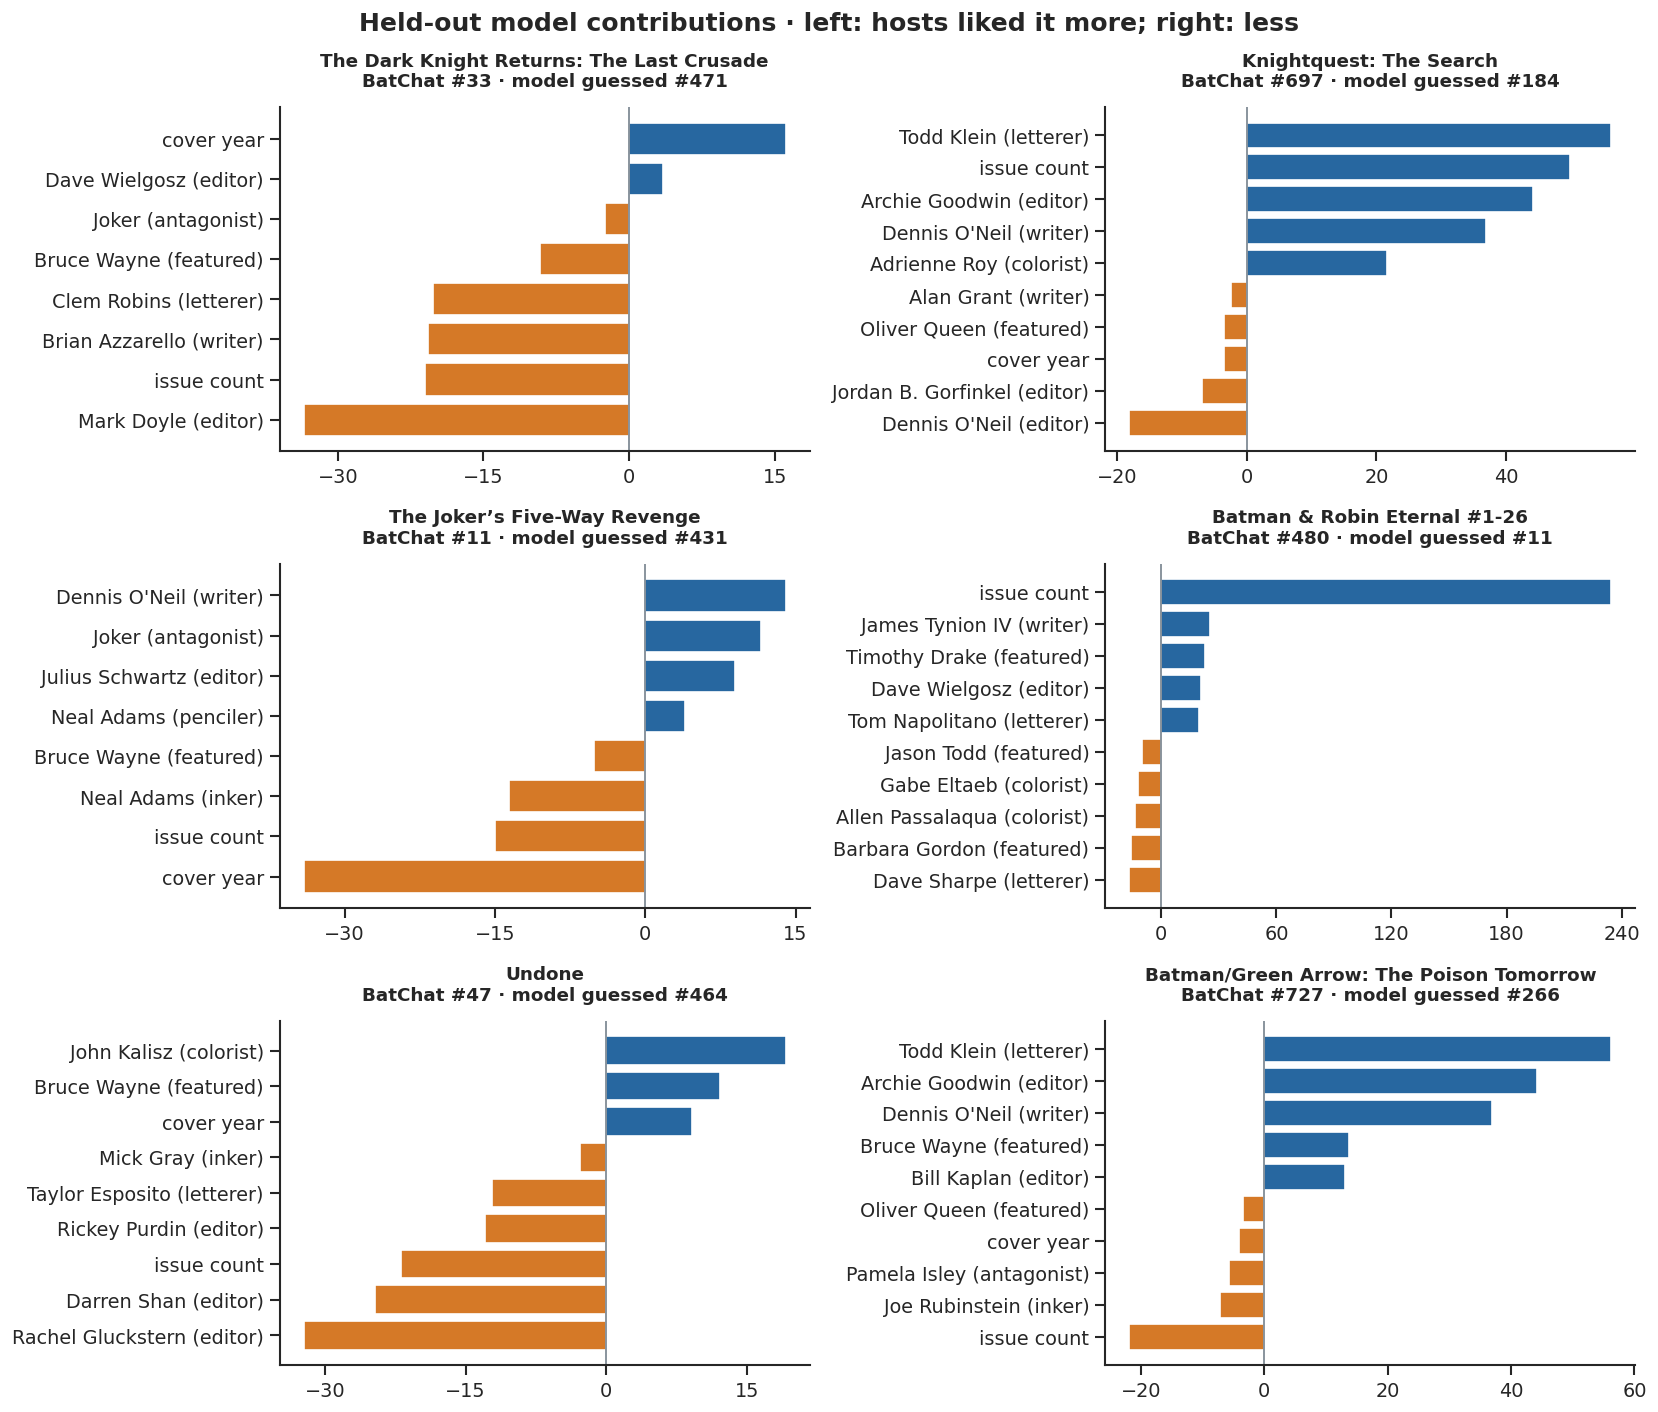

In [8]:
surprise = pd.Series(y.to_numpy() - held_out, index=stories.title)
picks = [*surprise.nlargest(3).index, *surprise.nsmallest(3).index]
contrib = held_shap.where(presence, 0).copy()
contrib.index = stories.title

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
for ax, title in zip(axes.T.flat, picks):
    parts = contrib.loc[title]
    weight_bars(ax, parts[parts.abs() > 1], 5)
    rank = int(stories.loc[stories.title.eq(title), "rank"].iloc[0])
    guess = int(N - held_out[stories.title.eq(title)][0])
    ax.set_title(f"{title}\nBatChat #{rank} · model guessed #{guess}", fontsize=11)
fig.suptitle(
    "Held-out model contributions · left: hosts liked it more; right: less", fontweight="bold"
)
fig.tight_layout()
plt.show()

These are explanations of the models, not the hosts. *Undone* (#47) is a useful counterexample: its credits cannot describe how the grief story reads. A large residual does not establish which missing quality mattered.

*Batman & Robin Eternal* (#480) exposes a different limitation: the model treats issue count as a linear effect. Its unusually long run can dominate the prediction. The reranking notebook examines these kinds of disagreements without treating the model as the correct ranking.

## What the evidence supports

- Magnitude and direction differ: a feature can matter strongly in a few books but little across the list.
- Story counts, linked groups and fold stability help distinguish a broad pattern from a fragile example.
- The model still misses by about 170 places. Its attributions explain its predictions, not the hosts' reasoning.

<details><summary>Methods notes</summary>

- **Model:** ridge regression (the penalty chosen by cross-validation from 0.1 to 1000), the same set-up as [the prediction notebook](https://www.kaggle.com/code/danofer/batchat-s-favorite-batman-stories). The one change: a name needs five stories for a weight, not three, to keep one-off credits out of the chart. Targets: BatChat score (740 − rank), Goodreads stars, RoundUp scores.
- **Stability** keeps a name only if its weight has the same sign and is larger than 10 in all five fold refits. A rough filter, not a significance test.
- **Shuffle test** scrambles whole groups of columns at once (`sklearn.inspection.permutation_importance` does the same one column at a time); groups keep correlated names together.
- **SHAP** for this linear model is weight × (value − background mean). Each explanation uses its held-out fit and training background. We verify that all contributions plus the baseline reconstruct the held-out prediction, then plot only the largest present-feature contributions.

</details>

Read next: [Twenty reranking cases](https://www.kaggle.com/code/danofer/which-batman-stories-deserve-a-second-look) · [Audience comparisons](https://www.kaggle.com/code/danofer/batchat-vs-the-crowd-where-batman-fans-disagree)